In [1]:
import sqlite3
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Connect to the local SQLite database stored in the data/ directory
DB_PATH = "../data/food_price_intelligence.db"
conn = sqlite3.connect(DB_PATH)

# Use SQL JOINs to flatten the normalized tables into a single analytical table
prices_sql = """
SELECT 
    dp.date,
    m.state,
    m.district,
    m.name AS market_name,
    c.name AS commodity,
    dp.min_price_inr,
    dp.max_price_inr,
    dp.modal_price_inr
FROM daily_prices dp
JOIN markets m ON dp.market_id = m.id
JOIN commodities c ON dp.commodity_id = c.id
ORDER BY dp.date ASC
"""

# parse_dates converts string dates into proper datetime64 objects for time-series operations
df_prices = pd.read_sql_query(prices_sql, conn, parse_dates=["date"])
df_weather = pd.read_sql_query(
    "SELECT * FROM weather_data ORDER BY date ASC", conn, parse_dates=["date"]
)
conn.close()

print(f"Total Price Records: {len(df_prices):,}")
print(f"Total Weather Records: {len(df_weather):,}")
print(
    f"Overall Price Date Span: {df_prices['date'].min().date()} to"
    f" {df_prices['date'].max().date()}\n"
)

# Group by state and commodity to see which pairs have the strongest historical depth
audit_summary = (
    df_prices.groupby(["state", "commodity"])
    .agg(
        total_rows=("modal_price_inr", "count"),
        unique_markets=("market_name", "nunique"),
        earliest_date=("date", "min"),
        latest_date=("date", "max"),
        avg_modal_price=("modal_price_inr", "mean"),
    )
    .reset_index()
    .sort_values(by=["state", "total_rows"], ascending=[True, False])
)

display(audit_summary)

Total Price Records: 52,150
Total Weather Records: 5,340
Overall Price Date Span: 2022-01-01 to 2026-11-13



,state,commodity,total_rows,unique_markets,earliest_date,latest_date,avg_modal_price
42,Andhra Pradesh,Tomato,5054,18,2022-01-01,2026-11-13,1977.453502
27,Andhra Pradesh,Onion,1373,4,2022-01-01,2026-11-13,1838.651857
14,Andhra Pradesh,Dry Chillies,927,10,2022-01-03,2026-11-13,14509.482201
17,Andhra Pradesh,Green Chilli,522,3,2022-01-01,2026-11-13,3911.206897
5,Andhra Pradesh,Brinjal,452,2,2022-01-01,2026-11-13,2441.039823
...,...,...,...,...,...,...,...
99,Maharashtra,Red gram/Arhar/Tur(whole),1,1,2026-11-13,2026-11-13,8605.000000
100,Maharashtra,Ridgeguard(Tori),1,1,2026-11-13,2026-11-13,3960.000000
101,Maharashtra,Seetapal,1,1,2026-11-13,2026-11-13,3500.000000
103,Maharashtra,Sweet Pumpkin,1,1,2026-11-13,2026-11-13,1400.000000


In [2]:
# 1. Check for invalid (<= 0) or missing modal prices
invalid_count = (
    df_prices["modal_price_inr"].isna() | (df_prices["modal_price_inr"] <= 0)
).sum()
print(f"Found {invalid_count} rows with missing or <= 0 modal prices.")

# Keep only valid positive price records
df_clean = df_prices[df_prices["modal_price_inr"] > 0].copy()

# 2. Create a join key ('region_name') that matches weather_data.region_name
# In weather_data, regions are stored as 'Nashik', 'Kolar', and 'Andhra Pradesh'
df_clean["region_name"] = np.where(
    df_clean["state"] == "Andhra Pradesh",
    "Andhra Pradesh",
    df_clean["district"],
)

# 3. Aggregate multiple mandis per region/day into a single daily benchmark price
# Using median alongside mean helps resist single-mandi data entry typos
daily_regional_prices = (
    df_clean.groupby(["region_name", "commodity", "date"])
    .agg(
        mandi_count=("market_name", "nunique"),
        median_modal_price=("modal_price_inr", "median"),
        mean_modal_price=("modal_price_inr", "mean"),
        min_price=("min_price_inr", "min"),
        max_price=("max_price_inr", "max"),
    )
    .reset_index()
)

# 4. Merge daily regional prices with daily weather metrics on (region_name, date)
df_merged = pd.merge(
    daily_regional_prices,
    df_weather[[
        "region_name",
        "date",
        "temperature_max_c",
        "temperature_min_c",
        "precipitation_mm",
    ]],
    on=["region_name", "date"],
    how="inner",  # Keeps dates where both price and weather observations exist
)

print(
    f"Merged daily region-commodity dataset shape: {df_merged.shape[0]:,}"
    f" rows x {df_merged.shape[1]} columns"
)
display(df_merged.head())

Found 0 rows with missing or <= 0 modal prices.
Merged daily region-commodity dataset shape: 18,873 rows x 11 columns


,region_name,commodity,date,mandi_count,median_modal_price,mean_modal_price,min_price,max_price,temperature_max_c,temperature_min_c,precipitation_mm
0,Andhra Pradesh,Bajra(Pearl Millet/Cumbu),2026-11-13,2,2955.0,2955.0,2900.0,3010.0,30.6,22.4,0.6
1,Andhra Pradesh,Bajra(Pearl Millet/Cumbu),2026-11-13,2,2955.0,2955.0,2900.0,3010.0,30.8,22.4,0.7
2,Andhra Pradesh,Bajra(Pearl Millet/Cumbu),2026-11-13,2,2955.0,2955.0,2900.0,3010.0,30.8,22.4,0.7
3,Andhra Pradesh,Banana,2026-11-13,5,1600.0,1990.0,800.0,4800.0,30.6,22.4,0.6
4,Andhra Pradesh,Banana,2026-11-13,5,1600.0,1990.0,800.0,4800.0,30.8,22.4,0.7


Correlation Matrix for Nashik - Onion:


,median_modal_price
median_modal_price,1.000000
rain_7d_rolling,0.160381
rain_lag_7d,0.189884
rain_lag_14d,0.249437
rain_lag_21d,0.304826
temperature_max_c,-0.311955


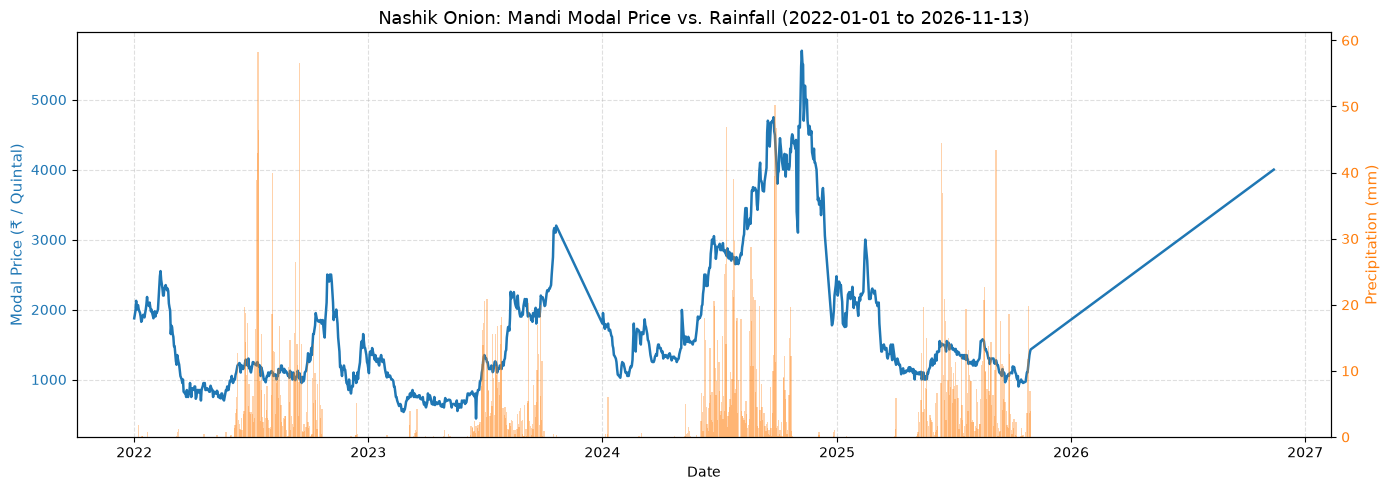

In [3]:
# Filter for a flagship hub-crop pair (change to 'Kolar' & 'Tomato' or 'Andhra Pradesh' & 'Dry Chillies' to inspect others)
TARGET_REGION = "Nashik"
TARGET_COMMODITY = "Onion"

subset = (
    df_merged[
        (df_merged["region_name"] == TARGET_REGION)
        & (df_merged["commodity"] == TARGET_COMMODITY)
    ]
    .sort_values("date")
    .copy()
)

# Create rolling 7-day rainfall and lagged rainfall features (shifted forward to align past rain with today's price)
subset["rain_7d_rolling"] = (
    subset["precipitation_mm"].rolling(window=7, min_periods=1).sum()
)
subset["rain_lag_7d"] = subset["rain_7d_rolling"].shift(7)
subset["rain_lag_14d"] = subset["rain_7d_rolling"].shift(14)
subset["rain_lag_21d"] = subset["rain_7d_rolling"].shift(21)

# Print Pearson correlation between lagged cumulative rainfall and modal price
corr_cols = [
    "median_modal_price",
    "rain_7d_rolling",
    "rain_lag_7d",
    "rain_lag_14d",
    "rain_lag_21d",
    "temperature_max_c",
]
print(f"Correlation Matrix for {TARGET_REGION} - {TARGET_COMMODITY}:")
display(subset[corr_cols].corr()[["median_modal_price"]])

# Dual-axis chart: Modal Price (₹/Quintal) vs. Daily Rainfall (mm)
fig, ax1 = plt.subplots(figsize=(14, 5))

ax1.plot(
    subset["date"],
    subset["median_modal_price"],
    color="#1f77b4",
    linewidth=1.8,
    label="Median Modal Price (₹/Quintal)",
)
ax1.set_xlabel("Date")
ax1.set_ylabel("Modal Price (₹ / Quintal)", color="#1f77b4", fontsize=11)
ax1.tick_params(axis="y", labelcolor="#1f77b4")
ax1.grid(True, linestyle="--", alpha=0.4)

# Twin axis for precipitation bars
ax2 = ax1.twinx()
ax2.bar(
    subset["date"],
    subset["precipitation_mm"],
    color="#ff7f0e",
    alpha=0.35,
    width=2,
    label="Daily Precipitation (mm)",
)
ax2.set_ylabel("Precipitation (mm)", color="#ff7f0e", fontsize=11)
ax2.tick_params(axis="y", labelcolor="#ff7f0e")

plt.title(
    f"{TARGET_REGION} {TARGET_COMMODITY}: Mandi Modal Price vs. Rainfall"
    f" ({subset['date'].min().date()} to {subset['date'].max().date()})",
    fontsize=13,
)
fig.tight_layout()
plt.show()